# Fine-tuning — YOLO com Offline Augmentation Direcionado

Detecção de `pothole` e `manhole_cover` (divisão 70/15/15, augmentation apenas no `train` para imagens com `manhole_cover`).

## 0. Dependências

In [1]:
%pip install -qU ultralytics pyyaml pandas matplotlib opencv-python-headless albumentations

Note: you may need to restart the kernel to use updated packages.


## 1. Ambiente e reprodutibilidade

In [2]:
import gc
import json
import platform
import random
import shutil
import subprocess
import sys
from collections import Counter
from datetime import datetime
from pathlib import Path

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import ultralytics
import yaml
from ultralytics import YOLO, settings

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print(f"PyTorch: {torch.__version__} | Ultralytics: {ultralytics.__version__} | Device: {gpu_name}")

/run/media/pedro-martins/Windows/Workspace/Study/UPE/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.15.0+rocm10.2.0 | Ultralytics: 8.4.220 | Device: AMD Radeon RX 7600


## 2. Caminhos e identificação do experimento

In [3]:
model_set = "yolo11s"
NEW_VERSION = False  # True cria nova versão; False reutiliza a última

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if p.name.lower() == "urbansense"), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(f"Pasta 'urbansense' não encontrada a partir de {cwd}.")

BASE_DATASET_DIR = (PROJECT_ROOT / "data" / "Potholes_dataset_dividido").resolve()
BASE_DATA_YAML = BASE_DATASET_DIR / "data.yaml"
if not BASE_DATA_YAML.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {BASE_DATA_YAML}")

DATASET_DIR = (PROJECT_ROOT / "data" / "Potholes_dataset_offline_augmented").resolve()
DATA_YAML = DATASET_DIR / "data.yaml"

RUNS_DIR = (PROJECT_ROOT / "runs").resolve()
ARTIFACTS_ROOT = (PROJECT_ROOT / "artifacts").resolve()
WEIGHTS_CACHE_DIR = (RUNS_DIR / "weights").resolve()

RUNS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_ROOT.mkdir(parents=True, exist_ok=True)
WEIGHTS_CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Força o Ultralytics a salvar runs e pesos base dentro de runs/
settings.update({
    "runs_dir": str(RUNS_DIR),
    "weights_dir": str(WEIGHTS_CACHE_DIR),
})

EXPERIMENT_PREFIX = f"potholes-{model_set}"
existing = [p for p in RUNS_DIR.glob(f"{EXPERIMENT_PREFIX}-v*") if p.is_dir()]
versions = [int(p.name.rsplit("-v", 1)[1]) for p in existing if p.name.rsplit("-v", 1)[1].isdigit()]

VERSION = max(versions, default=0) + 1 if NEW_VERSION else max(versions, default=1)
EXPERIMENT_NAME = f"{EXPERIMENT_PREFIX}-v{VERSION}"
RUN_NAME = EXPERIMENT_NAME
RUN_DIR = RUNS_DIR / RUN_NAME
ARTIFACTS_DIR = ARTIFACTS_ROOT / EXPERIMENT_NAME
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Experimento: {EXPERIMENT_NAME} | Run dir: {RUN_DIR}")

Experimento: potholes-yolo11s-v1 | Run dir: /run/media/pedro-martins/Windows/Workspace/Study/UPE/urbansense/runs/potholes-yolo11s-v1


## 2.1 Configuração e execução do Offline Augmentation

In [4]:
TARGET_CLASS = 1  # manhole_cover
AUGMENTATIONS_PER_PURE_IMAGE = 3
COPY_PASTE_PER_MIXED_BOX = 2  # Quantas vezes cada bueiro de imagem mista será colado
REBUILD_AUGMENTED_DATASET = False  # True apenas se quiser regerar o dataset do zero

AUGMENTATION_MARKER = DATASET_DIR / ".augmentation_complete.json"
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

offline_transform = A.Compose(
    [
        A.HorizontalFlip(p=0.5),
        A.Rotate(limit=5, border_mode=cv2.BORDER_CONSTANT, fill=0, p=0.4),
        A.OneOf(
            [
                # Night / Evening
                A.RandomBrightnessContrast(
                    brightness_limit=(-0.45, -0.15),
                    contrast_limit=(-0.20, 0.10),
                    p=1.0,
                ),
                # Sunset / Evening
                A.RGBShift(
                    r_shift_limit=(15, 40),
                    g_shift_limit=(-5, 15),
                    b_shift_limit=(-35, -10),
                    p=1.0,
                ),
                # Rain
                A.RandomRain(
                    slant_range=(-10, 10),
                    drop_length=15,
                    drop_width=1,
                    drop_color=(200, 200, 200),
                    blur_value=3,
                    brightness_coefficient=0.85,
                    rain_type="default",
                    p=1.0,
                ),
                # Sombras fortes
                A.RandomShadow(
                    shadow_roi=(0, 0.2, 1, 1),
                    num_shadows_limit=(1, 3),
                    shadow_dimension=5,
                    p=1.0,
                ),
            ],
            p=0.9,
        ),
    ],
    bbox_params=A.BboxParams(
        format="yolo",
        label_fields=["class_labels"],
        min_visibility=0.3,
    ),
)


def yolo_to_xyxy(box, img_w, img_h):
    cx, cy, w, h = box
    x1 = max(0, int((cx - w / 2) * img_w))
    y1 = max(0, int((cy - h / 2) * img_h))
    x2 = min(img_w, int((cx + w / 2) * img_w))
    y2 = min(img_h, int((cy + h / 2) * img_h))
    return x1, y1, x2, y2


def boxes_overlap(box_a, box_b):
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b
    return not (ax2 <= bx1 or ax1 >= bx2 or ay2 <= by1 or ay1 >= by2)


augmentation_completed = (
    DATASET_DIR.exists()
    and AUGMENTATION_MARKER.exists()
    and DATA_YAML.exists()
)

if REBUILD_AUGMENTED_DATASET or not augmentation_completed:
    if DATASET_DIR.exists():
        shutil.rmtree(DATASET_DIR)
    shutil.copytree(BASE_DATASET_DIR, DATASET_DIR)

    train_image_dir = BASE_DATASET_DIR / "images" / "train"
    train_label_dir = BASE_DATASET_DIR / "labels" / "train"

    generated = discarded = pure_eligible = mixed_sources = 0
    original_counts = Counter()
    generated_counts = Counter()

    pure_manhole_items = []
    negative_images = []
    manhole_crops = []

    # 1. Indexa imagens do train
    for image_path in sorted(train_image_dir.rglob("*")):
        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        relative_path = image_path.relative_to(train_image_dir)
        label_path = train_label_dir / relative_path.with_suffix(".txt")
        if not label_path.exists():
            continue

        lines = [
            line.split()
            for line in label_path.read_text(encoding="utf-8").splitlines()
            if line.strip()
        ]

        if not lines:
            negative_images.append(image_path)
            continue

        class_ids = [int(line[0]) for line in lines]
        boxes = [[float(v) for v in line[1:]] for line in lines]

        for cid in class_ids:
            original_counts[cid] += 1

        if TARGET_CLASS not in class_ids:
            continue

        if set(class_ids) == {TARGET_CLASS}:
            pure_manhole_items.append((image_path, relative_path, class_ids, boxes))
        else:
            mixed_sources += 1
            img = cv2.imread(str(image_path))
            if img is None:
                continue
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            h, w, _ = img_rgb.shape
            for cid, box in zip(class_ids, boxes):
                if cid == TARGET_CLASS:
                    x1, y1, x2, y2 = yolo_to_xyxy(box, w, h)
                    if (x2 - x1) >= 12 and (y2 - y1) >= 12:
                        manhole_crops.append(img_rgb[y1:y2, x1:x2])

    # 2. Augmentation padrão nas imagens puras (só manhole_cover)
    for image_path, relative_path, class_ids, boxes in pure_manhole_items:
        img = cv2.imread(str(image_path))
        if img is None:
            continue
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        pure_eligible += 1

        for aug_id in range(AUGMENTATIONS_PER_PURE_IMAGE):
            augmented = offline_transform(
                image=img_rgb,
                bboxes=boxes,
                class_labels=class_ids,
            )
            if not augmented["bboxes"]:
                discarded += 1
                continue

            suffix = f"_pure_aug{aug_id + 1}"
            out_img = DATASET_DIR / "images" / "train" / relative_path.parent / f"{relative_path.stem}{suffix}.jpg"
            out_lbl = DATASET_DIR / "labels" / "train" / relative_path.parent / f"{relative_path.stem}{suffix}.txt"
            out_img.parent.mkdir(parents=True, exist_ok=True)
            out_lbl.parent.mkdir(parents=True, exist_ok=True)

            cv2.imwrite(str(out_img), cv2.cvtColor(augmented["image"], cv2.COLOR_RGB2BGR))
            with out_lbl.open("w", encoding="utf-8") as f:
                for cid, box in zip(augmented["class_labels"], augmented["bboxes"]):
                    f.write(f"{int(cid)} " + " ".join(f"{v:.8f}" for v in box) + "\n")
                    generated_counts[int(cid)] += 1
            generated += 1

    # 3. Copy-Paste dos bueiros extraídos de imagens mistas em fundos sem pothole
    host_pool = negative_images if negative_images else [item[0] for item in pure_manhole_items]

    if host_pool and manhole_crops:
        for crop_idx, crop in enumerate(manhole_crops):
            ch, cw, _ = crop.shape
            mask = np.zeros((ch, cw), dtype=np.float32)
            cv2.ellipse(mask, (cw // 2, ch // 2), (int(cw * 0.48), int(ch * 0.48)), 0, 0, 360, 1.0, -1)
            mask = cv2.GaussianBlur(mask, (0, 0), sigmaX=max(1.5, min(cw, ch) * 0.05))
            mask_3c = mask[:, :, None]

            for copy_id in range(COPY_PASTE_PER_MIXED_BOX):
                host_path = random.choice(host_pool)
                host_img = cv2.imread(str(host_path))
                if host_img is None:
                    continue
                host_rgb = cv2.cvtColor(host_img, cv2.COLOR_BGR2RGB).copy()
                hh, hw, _ = host_rgb.shape

                host_rel = host_path.relative_to(train_image_dir)
                host_lbl_path = train_label_dir / host_rel.with_suffix(".txt")
                existing_boxes = []
                existing_cids = []
                occupied_xyxy = []

                if host_lbl_path.exists():
                    for line in host_lbl_path.read_text(encoding="utf-8").splitlines():
                        if line.strip():
                            parts = line.split()
                            cid = int(parts[0])
                            box = [float(v) for v in parts[1:]]
                            existing_cids.append(cid)
                            existing_boxes.append(box)
                            occupied_xyxy.append(yolo_to_xyxy(box, hw, hh))

                scale = min(1.0, (hw * 0.25) / max(cw, 1), (hh * 0.25) / max(ch, 1))
                nw, nh = max(12, int(cw * scale)), max(12, int(ch * scale))
                if nw >= hw or nh >= hh:
                    continue

                crop_resized = cv2.resize(crop, (nw, nh), interpolation=cv2.INTER_AREA)
                mask_resized = cv2.resize(mask_3c, (nw, nh), interpolation=cv2.INTER_AREA)[:, :, None]

                y_min_limit = int(hh * 0.45) if hh * 0.45 + nh < hh else 0
                placed = False
                for _ in range(15):
                    px1 = random.randint(0, hw - nw)
                    py1 = random.randint(y_min_limit, hh - nh)
                    candidate_xyxy = (px1, py1, px1 + nw, py1 + nh)
                    if not any(boxes_overlap(candidate_xyxy, occ) for occ in occupied_xyxy):
                        placed = True
                        break

                if not placed:
                    continue

                roi = host_rgb[py1:py1 + nh, px1:px1 + nw].astype(np.float32)
                blended = crop_resized.astype(np.float32) * mask_resized + roi * (1.0 - mask_resized)
                host_rgb[py1:py1 + nh, px1:px1 + nw] = np.clip(blended, 0, 255).astype(np.uint8)

                new_box = [
                    (px1 + nw / 2) / hw,
                    (py1 + nh / 2) / hh,
                    nw / hw,
                    nh / hh,
                ]
                all_boxes = existing_boxes + [new_box]
                all_cids = existing_cids + [TARGET_CLASS]

                augmented = offline_transform(
                    image=host_rgb,
                    bboxes=all_boxes,
                    class_labels=all_cids,
                )
                if not augmented["bboxes"]:
                    discarded += 1
                    continue

                stem = f"cp_manhole_{crop_idx:04d}_{copy_id + 1}"
                out_img = DATASET_DIR / "images" / "train" / f"{stem}.jpg"
                out_lbl = DATASET_DIR / "labels" / "train" / f"{stem}.txt"

                cv2.imwrite(str(out_img), cv2.cvtColor(augmented["image"], cv2.COLOR_RGB2BGR))
                with out_lbl.open("w", encoding="utf-8") as f:
                    for cid, box in zip(augmented["class_labels"], augmented["bboxes"]):
                        f.write(f"{int(cid)} " + " ".join(f"{v:.8f}" for v in box) + "\n")
                        generated_counts[int(cid)] += 1
                generated += 1

    augmentation_metadata = {
        "target_class": TARGET_CLASS,
        "pure_images_augmented": pure_eligible,
        "mixed_images_cropped": mixed_sources,
        "crops_extracted": len(manhole_crops),
        "generated_images": generated,
        "discarded_transformations": discarded,
        "original_instance_counts": dict(original_counts),
        "generated_instance_counts": dict(generated_counts),
        "seed": SEED,
        "created_at": datetime.now().astimezone().isoformat(),
    }
    AUGMENTATION_MARKER.write_text(
        json.dumps(augmentation_metadata, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )
    print(
        f"Augmentation concluído — Puras: {pure_eligible} | Recortes mistos: {len(manhole_crops)} | "
        f"Imagens geradas: {generated} | Descartadas: {discarded}"
    )
else:
    augmentation_metadata = json.loads(AUGMENTATION_MARKER.read_text(encoding="utf-8"))
    print("Dataset aumentado reutilizado.")

Dataset aumentado reutilizado.


## 2.2 Atualização do data.yaml

In [5]:
config_augmented = yaml.safe_load(BASE_DATA_YAML.read_text(encoding="utf-8"))
config_augmented["path"] = str(DATASET_DIR.resolve())
DATA_YAML.write_text(yaml.safe_dump(config_augmented, sort_keys=False, allow_unicode=True), encoding="utf-8")

original_counts = Counter({int(k): int(v) for k, v in augmentation_metadata["original_instance_counts"].items()})
generated_counts = Counter({int(k): int(v) for k, v in augmentation_metadata["generated_instance_counts"].items()})
final_counts = original_counts + generated_counts

distribution_comparison = pd.DataFrame([
    {
        "classe_id": cid,
        "classe": "pothole" if cid == 0 else "manhole_cover",
        "original": original_counts[cid],
        "adicionadas": generated_counts[cid],
        "total_final": final_counts[cid],
    }
    for cid in sorted(final_counts)
])

distribution_comparison.to_csv(ARTIFACTS_DIR / "distribuicao_augmentation.csv", index=False)
display(distribution_comparison)

,classe_id,classe,original,adicionadas,total_final
0,0,pothole,2240,0,2240
1,1,manhole_cover,312,671,983


## 3. Auditoria de integridade e anotações

In [6]:
config = yaml.safe_load(DATA_YAML.read_text(encoding="utf-8"))
class_names_raw = config.get("names", {})
class_names = (
    {i: name for i, name in enumerate(class_names_raw)}
    if isinstance(class_names_raw, list)
    else {int(k): v for k, v in class_names_raw.items()}
)

dataset_rows = []
class_distribution = {int(k): 0 for k in class_names}
annotation_issues = []

for split in ("train", "val", "test"):
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    image_files = sorted(p for p in image_dir.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS) if image_dir.exists() else []
    label_files = sorted(label_dir.rglob("*.txt")) if label_dir.exists() else []

    image_keys = {(p.relative_to(image_dir).parent, p.stem): p for p in image_files}
    label_keys = {(p.relative_to(label_dir).parent, p.stem): p for p in label_files}

    missing_labels = sorted(set(image_keys) - set(label_keys))
    orphan_labels = sorted(set(label_keys) - set(image_keys))

    negative_images = valid_object_images = invalid_label_files = 0
    split_counts = {int(k): 0 for k in class_names}

    for key in image_keys:
        label_path = label_keys.get(key)
        if label_path is None:
            continue

        lines = [line.strip() for line in label_path.read_text(encoding="utf-8").splitlines() if line.strip()]
        if not lines:
            negative_images += 1
            continue

        valid_in_file = 0
        for line_number, line in enumerate(lines, start=1):
            parts = line.split()
            try:
                if len(parts) != 5:
                    raise ValueError("Esperados 5 valores")
                class_id = int(float(parts[0]))
                coords = np.asarray([float(v) for v in parts[1:]], dtype=float)

                if class_id not in class_names:
                    raise ValueError(f"class_id desconhecido: {class_id}")
                if not np.isfinite(coords).all() or (coords < 0).any() or (coords > 1).any():
                    raise ValueError("Coordenadas inválidas ou fora de [0, 1]")
                if coords[2] <= 0 or coords[3] <= 0:
                    raise ValueError("Largura/altura não positivas")

                split_counts[class_id] += 1
                class_distribution[class_id] += 1
                valid_in_file += 1
            except Exception as exc:
                invalid_label_files += 1
                annotation_issues.append({"split": split, "arquivo": str(label_path), "linha": line_number, "erro": str(exc)})

        if valid_in_file:
            valid_object_images += 1

    dataset_rows.append({
        "split": split,
        "imagens": len(image_files),
        "arquivos_txt": len(label_files),
        "imagens_sem_txt": len(missing_labels),
        "txt_sem_imagem": len(orphan_labels),
        "imagens_com_objetos_validos": valid_object_images,
        "imagens_negativas_txt_vazio": negative_images,
        "anotacoes_invalidas": invalid_label_files,
        **{f"caixas_{class_names[k]}": v for k, v in split_counts.items()},
    })

dataset_summary = pd.DataFrame(dataset_rows)
display(dataset_summary)

if annotation_issues:
    pd.DataFrame(annotation_issues).to_csv(ARTIFACTS_DIR / "anotacoes_invalidas.csv", index=False)

if dataset_summary[["imagens", "arquivos_txt"]].eq(0).any().any():
    raise RuntimeError("Split sem imagens ou arquivos de anotação.")
if (dataset_summary["imagens_sem_txt"] > 0).any() or (dataset_summary["txt_sem_imagem"] > 0).any():
    raise RuntimeError("Encontradas imagens sem TXT ou anotações órfãs.")
if (dataset_summary["anotacoes_invalidas"] > 0).any():
    raise RuntimeError("Encontradas anotações inválidas.")

class_distribution_df = pd.DataFrame([{"classe_id": k, "classe": class_names[k], "caixas": v} for k, v in class_distribution.items()])
dataset_summary.to_csv(ARTIFACTS_DIR / "auditoria_dataset.csv", index=False)
class_distribution_df.to_csv(ARTIFACTS_DIR / "distribuicao_classes.csv", index=False)

,split,imagens,arquivos_txt,imagens_sem_txt,txt_sem_imagem,imagens_com_objetos_validos,imagens_negativas_txt_vazio,anotacoes_invalidas,caixas_pothole,caixas_manhole_cover
0,train,2125,2125,0,0,1713,412,0,2240,983
1,val,315,315,0,0,226,89,0,459,66
2,test,315,315,0,0,227,88,0,467,64


## 4. Configuração do treinamento e registro do ambiente

In [7]:
BASE_MODEL = str(WEIGHTS_CACHE_DIR / f"{model_set}.pt")
EPOCHS = 70
IMAGE_SIZE = 768
BATCH_SIZE = 4
PATIENCE = 10
DEVICE = 0 if torch.cuda.is_available() else "cpu"
WORKERS = 2

training_config = {
    "model": f"{model_set}.pt",
    "epochs": EPOCHS,
    "imgsz": IMAGE_SIZE,
    "batch": BATCH_SIZE,
    "patience": PATIENCE,
    "device": DEVICE,
    "workers": WORKERS,
    "rect": False,
    "seed": SEED,
    "pretrained": True,
    "data_yaml": str(DATA_YAML),
    "dataset": str(DATASET_DIR),
    "augmentation": "offline_targeted_copypaste",
    "target_class": TARGET_CLASS,
    "augmentations_per_pure_image": AUGMENTATIONS_PER_PURE_IMAGE,
    "copy_paste_per_mixed_box": COPY_PASTE_PER_MIXED_BOX,
    "created_at": datetime.now().astimezone().isoformat(),
}
(ARTIFACTS_DIR / "configuracao_treino.json").write_text(json.dumps(training_config, indent=2, ensure_ascii=False), encoding="utf-8")

environment = {
    "python": sys.version,
    "platform": platform.platform(),
    "processor": platform.processor(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "ultralytics": ultralytics.__version__,
    "albumentations": A.__version__,
    "opencv": cv2.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "cuda_available": torch.cuda.is_available(),
    "device_name": gpu_name,
}
(ARTIFACTS_DIR / "ambiente.json").write_text(json.dumps(environment, indent=2, ensure_ascii=False), encoding="utf-8")

ONLINE_AUG_PARAMS = {
    "mosaic": 1.0,       # Combina 4 imagens (fecha nas últimas 10 épocas via close_mosaic=10)
    "mixup": 0.0,        # Mantém 0.0 para não gerar transparência artificial em buracos/bueiros
    "copy_paste": 0.0,   # Já feito de forma direcionada no offline
    "degrees": 0.0,
    "translate": 0.1,
    "scale": 0.5,        # Varia distância/tamanho dos buracos e bueiros
    "shear": 0.0,
    "perspective": 0.0,
    "fliplr": 0.5,       # Espelhamento horizontal
    "flipud": 0.0,       # Mantém 0.0 (asfalto não fica de cabeça para baixo)
    "hsv_h": 0.015,
    "hsv_s": 0.4,        # Suavizado (padrão é 0.7) pois o offline já altera cores/chuva
    "hsv_v": 0.25,       # Suavizado (padrão é 0.4) pois o offline já escurece para noite/sombra
    "erasing": 0.2,      # Oclusão leve (padrão é 0.4)
}

freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True, check=False)
(ARTIFACTS_DIR / "pip_freeze.txt").write_text(freeze.stdout, encoding="utf-8")

2413

## 5. Fine-tuning

In [8]:
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    # Limita a 85% da VRAM (8 GB na RX 7600) para evitar hard crash do driver ROCm/amdgpu
    torch.cuda.set_per_process_memory_fraction(0.85, device=0)

BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
LAST_WEIGHTS = RUN_DIR / "weights" / "last.pt"
RESULTS_CSV = RUN_DIR / "results.csv"

rows = pd.read_csv(RESULTS_CSV).to_dict("records") if RESULTS_CSV.exists() else []
training_completed = len(rows) >= EPOCHS and BEST_WEIGHTS.exists()

if training_completed:
    print(f"Treinamento já concluído ({len(rows)}/{EPOCHS} épocas).")
    model = YOLO(str(BEST_WEIGHTS))
elif LAST_WEIGHTS.exists():
    checkpoint = torch.load(LAST_WEIGHTS, map_location="cpu", weights_only=False)
    if int(checkpoint.get("epoch", -1)) < 0 or checkpoint.get("optimizer") is None:
        raise RuntimeError("Checkpoint não permite retomada. Defina NEW_VERSION=True.")
    print("Retomando treinamento a partir do último checkpoint.")
    model = YOLO(str(LAST_WEIGHTS))
    model.train(resume=True)
else:
    model = YOLO(BASE_MODEL)
    model.train(
        data=str(DATA_YAML),
        epochs=EPOCHS,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        patience=PATIENCE,
        device=DEVICE,
        workers=WORKERS,
        seed=SEED,
        deterministic=True,
        pretrained=True,
        project=str(RUNS_DIR),
        name=RUN_NAME,
        exist_ok=True,
        plots=True,
        save=True,
        verbose=True,
        rect=False,
        **ONLINE_AUG_PARAMS
    )

if not BEST_WEIGHTS.exists() or not RESULTS_CSV.exists():
    raise FileNotFoundError("Artefatos de treinamento (best.pt ou results.csv) não encontrados.")

model = YOLO(str(BEST_WEIGHTS))

Ultralytics 8.4.220 🚀 Python-3.14.4 torch-2.15.0+rocm10.2.0 CUDA:0 (AMD Radeon RX 7600, 8176MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/run/media/pedro-martins/Windows/Workspace/Study/UPE/urbansense/data/Potholes_dataset_offline_augmented/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=70, erasing=0.2, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.25, imgsz=768, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/run/media/pedro-martins

## 6. Curvas e métricas por época

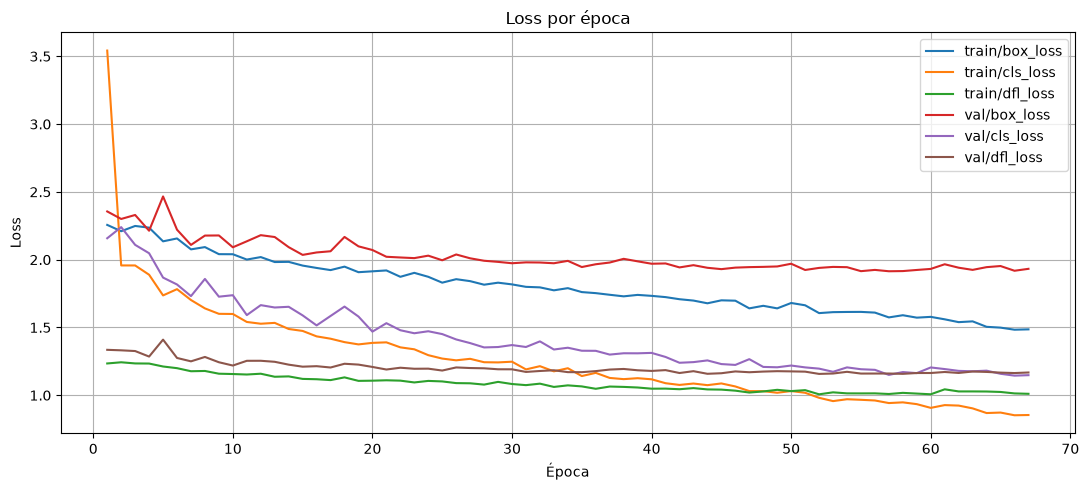

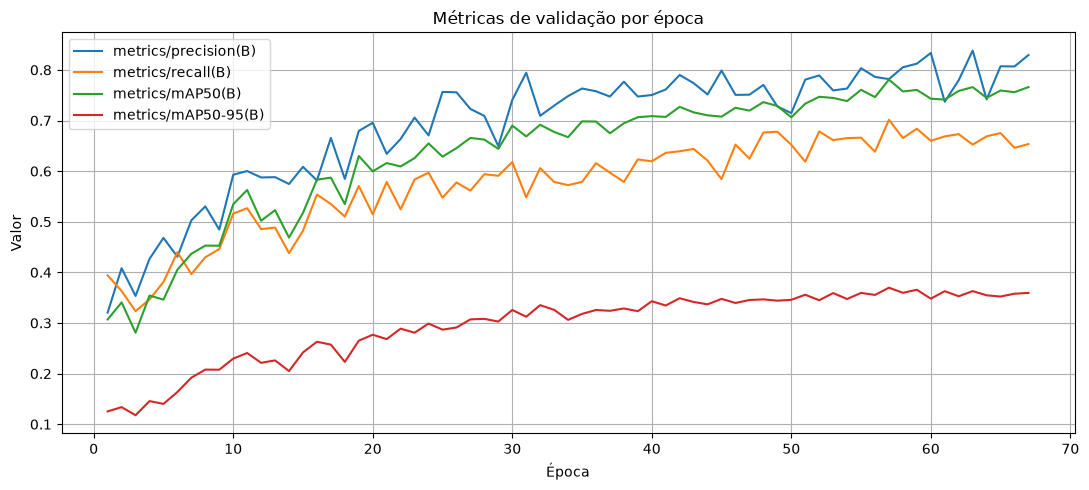

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
62,63,3560.94,1.54496,0.90318,1.02818,0.83818,0.65231,0.76599,0.36296,1.92473,1.17675,1.17508,0.000205,0.000205,0.000205
63,64,3617.09,1.50469,0.86875,1.02760,0.74176,0.66870,0.74473,0.35467,1.94483,1.18134,1.17200,0.000182,0.000182,0.000182
64,65,3673.46,1.49873,0.87233,1.02427,0.80715,0.67519,0.75927,0.35222,1.95306,1.15829,1.16685,0.000158,0.000158,0.000158
65,66,3729.86,1.48344,0.85240,1.01354,0.80680,0.64597,0.75595,0.35783,1.91817,1.14463,1.16376,0.000135,0.000135,0.000135
66,67,3786.17,1.48598,0.85419,1.01064,0.82942,0.65355,0.76604,0.35938,1.93245,1.14810,1.16783,0.000111,0.000111,0.000111


In [9]:
results_df = pd.read_csv(RESULTS_CSV)
results_df.columns = [c.strip() for c in results_df.columns]
results_df.to_csv(ARTIFACTS_DIR / "results.csv", index=False)

loss_cols = [c for c in results_df.columns if "loss" in c.lower() and pd.api.types.is_numeric_dtype(results_df[c])]
metric_cols = [c for c in results_df.columns if c.startswith("metrics/") and pd.api.types.is_numeric_dtype(results_df[c])]

if loss_cols:
    ax = results_df.plot(x="epoch", y=loss_cols, figsize=(11, 5), title="Loss por época", xlabel="Época", ylabel="Loss", grid=True)
    plt.tight_layout()
    plt.savefig(ARTIFACTS_DIR / "curvas_loss.png", dpi=150)
    plt.show()

if metric_cols:
    ax = results_df.plot(x="epoch", y=metric_cols, figsize=(11, 5), title="Métricas de validação por época", xlabel="Época", ylabel="Valor", grid=True)
    plt.tight_layout()
    plt.savefig(ARTIFACTS_DIR / "curvas_metricas.png", dpi=150)
    plt.show()

display(results_df.tail(5))

## 7. Avaliação no teste e registro final

In [10]:
test_metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True,
    project=str(RUNS_DIR),
    name=f"{RUN_NAME}-test",
    exist_ok=True,
    rect=True,
)

box = test_metrics.box
metrics_summary = {
    "experimento": EXPERIMENT_NAME,
    "modelo": f"{model_set}.pt",
    "split": "test",
    "precision": float(box.mp),
    "recall": float(box.mr),
    "mAP50": float(box.map50),
    "mAP50_95": float(box.map),
    "fitness": float(box.fitness()) if hasattr(box, "fitness") else None,
    "weights": str(BEST_WEIGHTS.resolve()),
    "evaluated_at": datetime.now().astimezone().isoformat(),
}
metrics_path = ARTIFACTS_DIR / "metricas_teste.json"
metrics_path.write_text(json.dumps(metrics_summary, indent=2, ensure_ascii=False), encoding="utf-8")

# Métricas por classe
test_label_dir = DATASET_DIR / "labels" / "test"
class_counts = {int(k): 0 for k in class_names}
for label_file in test_label_dir.rglob("*.txt"):
    for line in label_file.read_text(encoding="utf-8").splitlines():
        if line.strip():
            cid = int(line.split()[0])
            class_counts[cid] = class_counts.get(cid, 0) + 1

per_class_rows = [
    {
        "classe_id": int(cid),
        "classe": class_names.get(int(cid), str(cid)),
        "precision": float(box.p[idx]) if len(box.p) > idx else np.nan,
        "recall": float(box.r[idx]) if len(box.r) > idx else np.nan,
        "AP50": float(box.ap50[idx]),
        "AP50-95": float(box.ap[idx]),
        "caixas_reais_no_teste": class_counts.get(int(cid), 0),
    }
    for idx, cid in enumerate(box.ap_class_index)
]
per_class_df = pd.DataFrame(per_class_rows)
per_class_df.to_csv(ARTIFACTS_DIR / "metricas_por_classe.csv", index=False)

# Registro consolidado
report = {
    "experiment": EXPERIMENT_NAME,
    "created_at": datetime.now().astimezone().isoformat(),
    "configuration": training_config,
    "environment": environment,
    "augmentation": augmentation_metadata,
    "dataset_audit": dataset_rows,
    "class_distribution": class_distribution,
    "test_metrics": metrics_summary,
    "per_class_metrics": per_class_rows,
    "artifacts": {
        "training_results": str((ARTIFACTS_DIR / "results.csv").resolve()),
        "test_metrics": str(metrics_path.resolve()),
        "per_class_metrics": str((ARTIFACTS_DIR / "metricas_por_classe.csv").resolve()),
        "augmentation_distribution": str((ARTIFACTS_DIR / "distribuicao_augmentation.csv").resolve()),
        "best_weights": str(BEST_WEIGHTS.resolve()),
        "last_weights": str(LAST_WEIGHTS.resolve()),
    },
}
(ARTIFACTS_DIR / "registro_experimento.json").write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding="utf-8")

display(pd.DataFrame([metrics_summary]))
display(per_class_df)

Ultralytics 8.4.220 🚀 Python-3.14.4 torch-2.15.0+rocm10.2.0 CUDA:0 (AMD Radeon RX 7600, 8176MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 895.5±131.0 MB/s, size: 457.5 KB)
val: Scanning /run/media/pedro-martins/Windows/Workspace/Study/UPE/urbansense/data/Potholes_dataset_offline_augmented/labels/test/Clear_weather... 315 images, 88 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 315/315 4.6Kit/s 0.1s
val: New cache created: /run/media/pedro-martins/Windows/Workspace/Study/UPE/urbansense/data/Potholes_dataset_offline_augmented/labels/test/Clear_weather.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 79/79 5.9it/s 13.4s<0.1s
                   all        315        531      0.791      0.695       0.76      0.348
               pothole        218        467      0.712      0.658      0.709      0.284
         manhole_cover         45     

,experimento,modelo,split,precision,recall,mAP50,mAP50_95,fitness,weights,evaluated_at
0,potholes-yolo11s-v1,yolo11s.pt,test,0.791212,0.694928,0.759518,0.348325,0.348325,/run/media/pedro-martins/Windows/Workspace/Stu...,2026-11-28T00:57:55.597054-03:00


,classe_id,classe,precision,recall,AP50,AP50-95,caixas_reais_no_teste
0,0,pothole,0.712407,0.657741,0.708689,0.284255,467
1,1,manhole_cover,0.870017,0.732116,0.810347,0.412394,64
